# Ejemplos completos de la clase 3
El mismo programa está incluido en el anexo del Word Tema. Todos los datos se generan aquí o se cargan desde los conjuntos incorporados en scikit-learn. Las cuatro figuras se guardan en Figuras. Fuente del código: elaboración propia para el curso.

Comunidades 4 MSE prueba AE8 0.02650672119108422


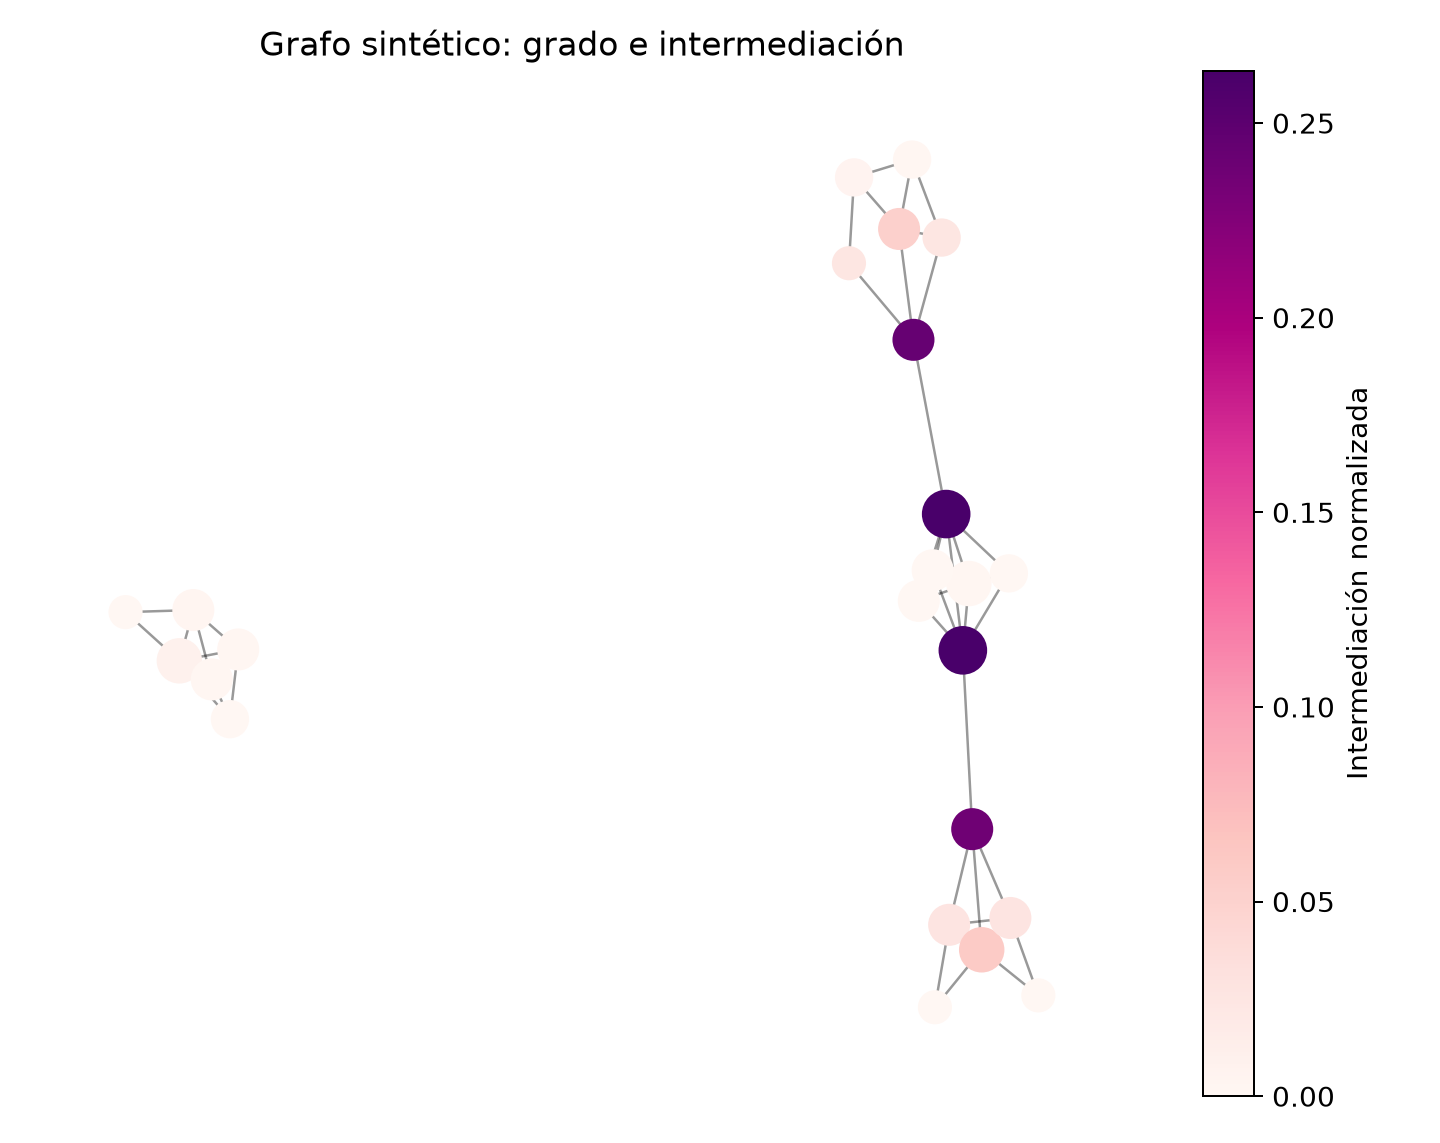

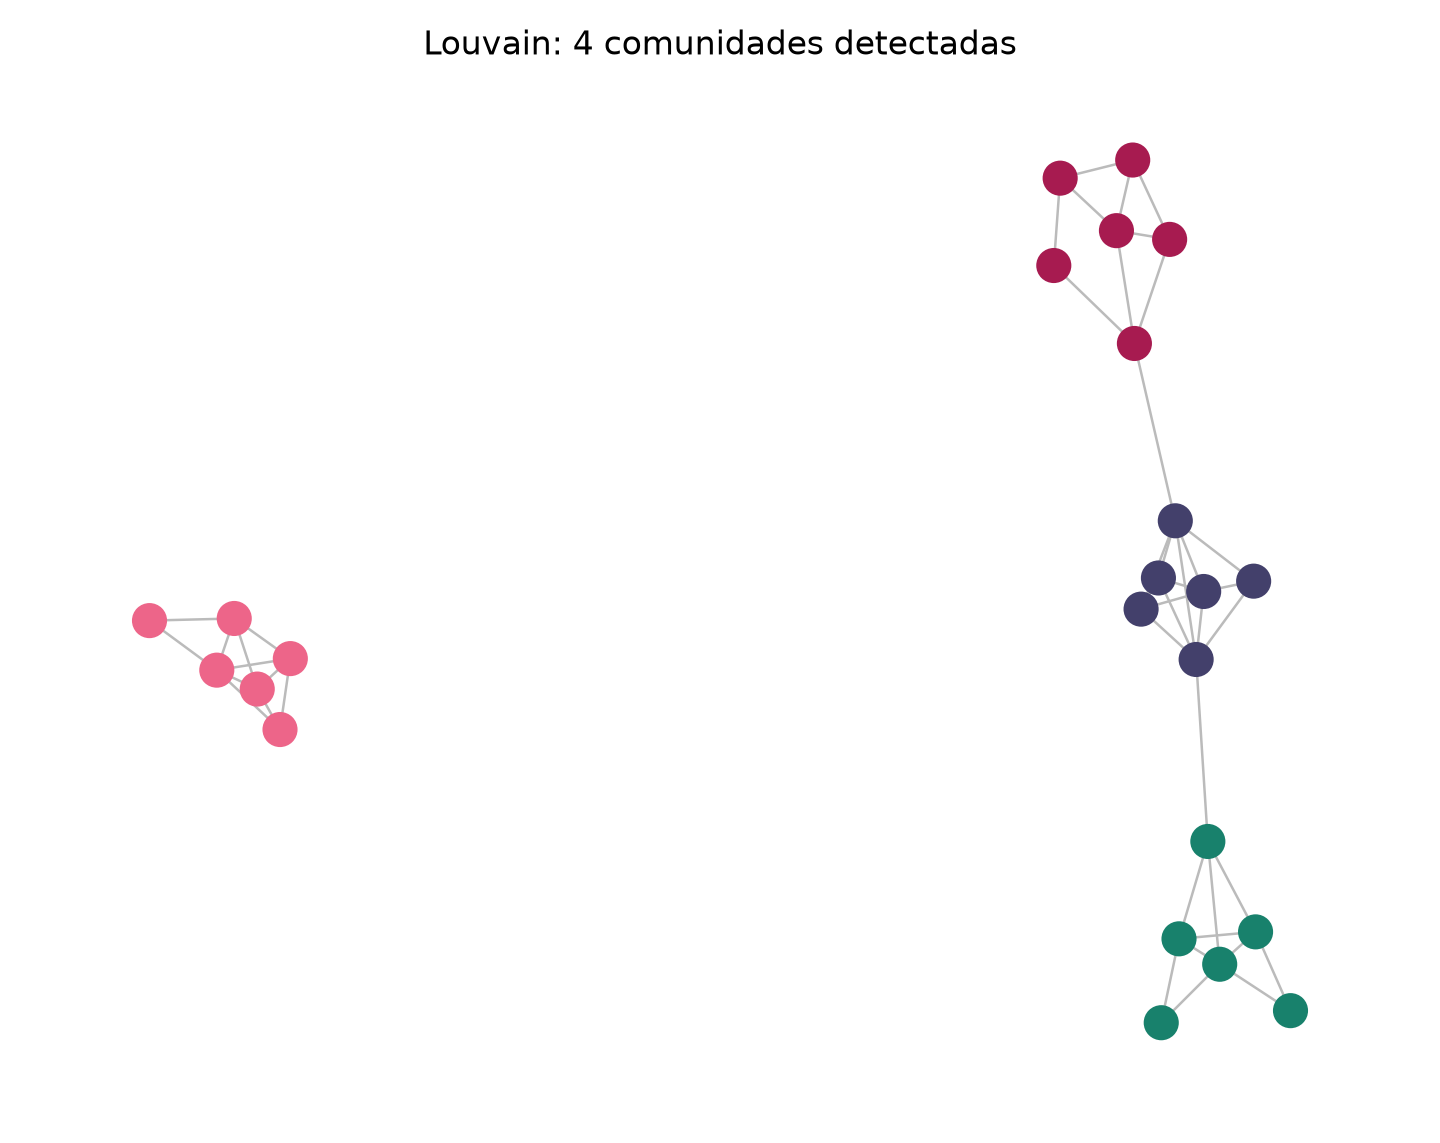

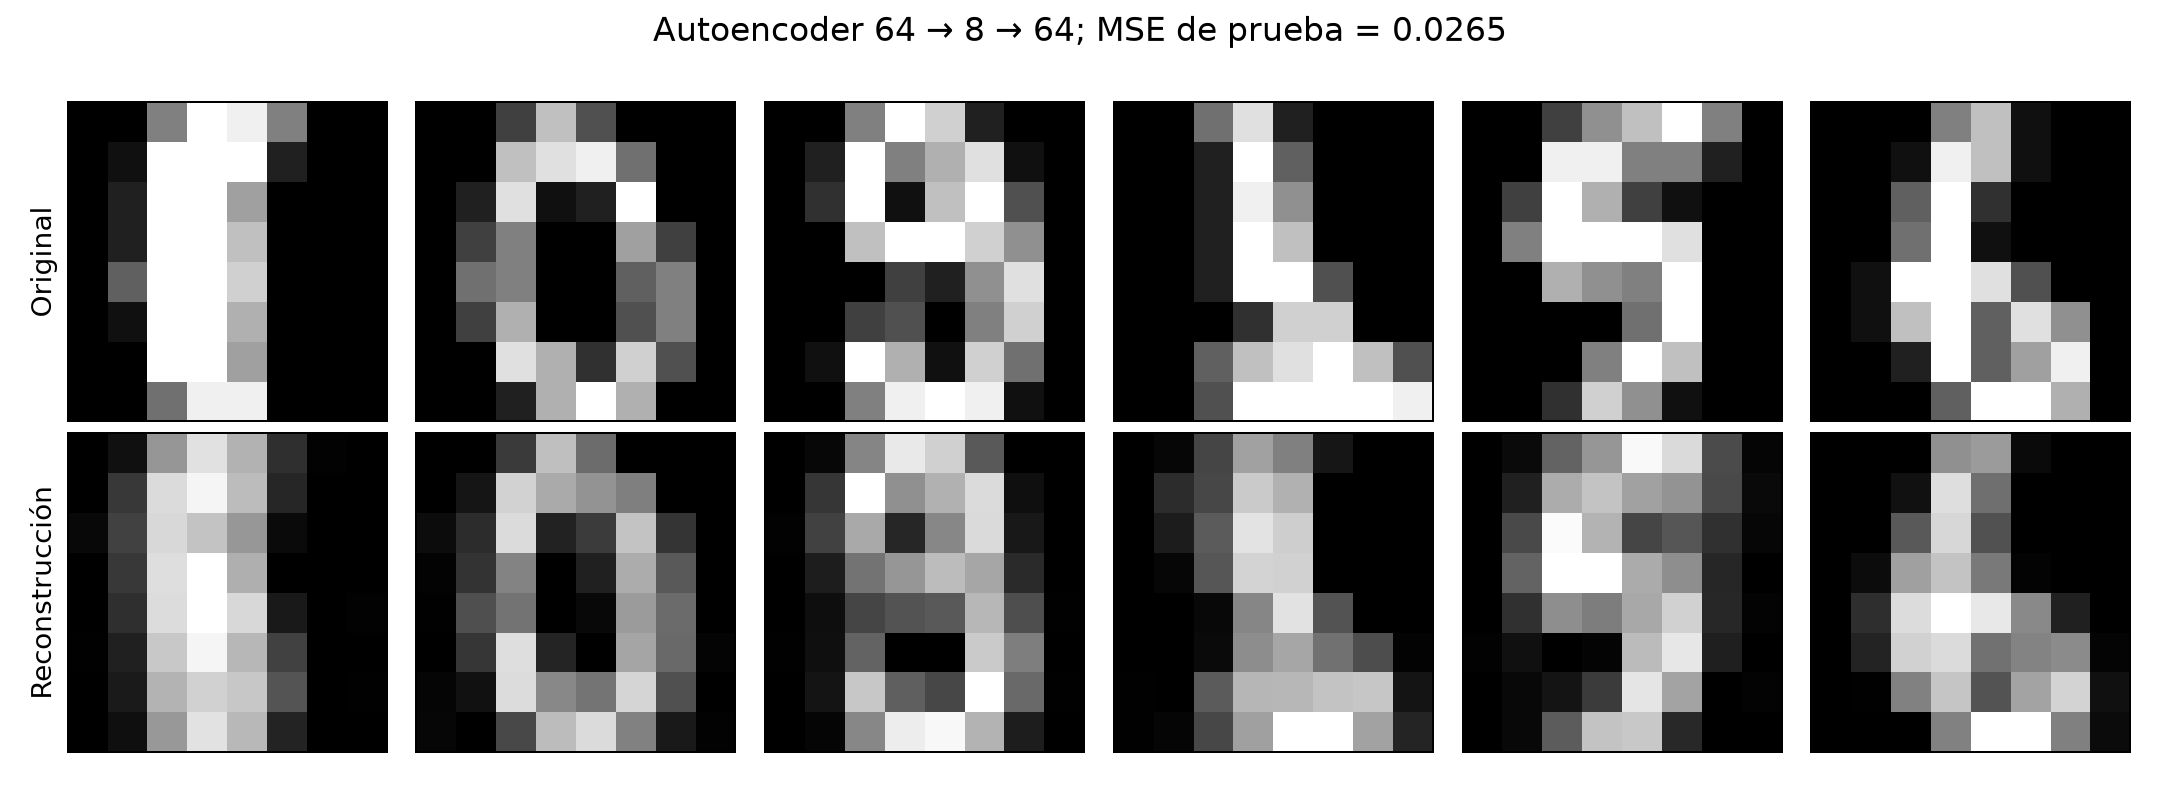

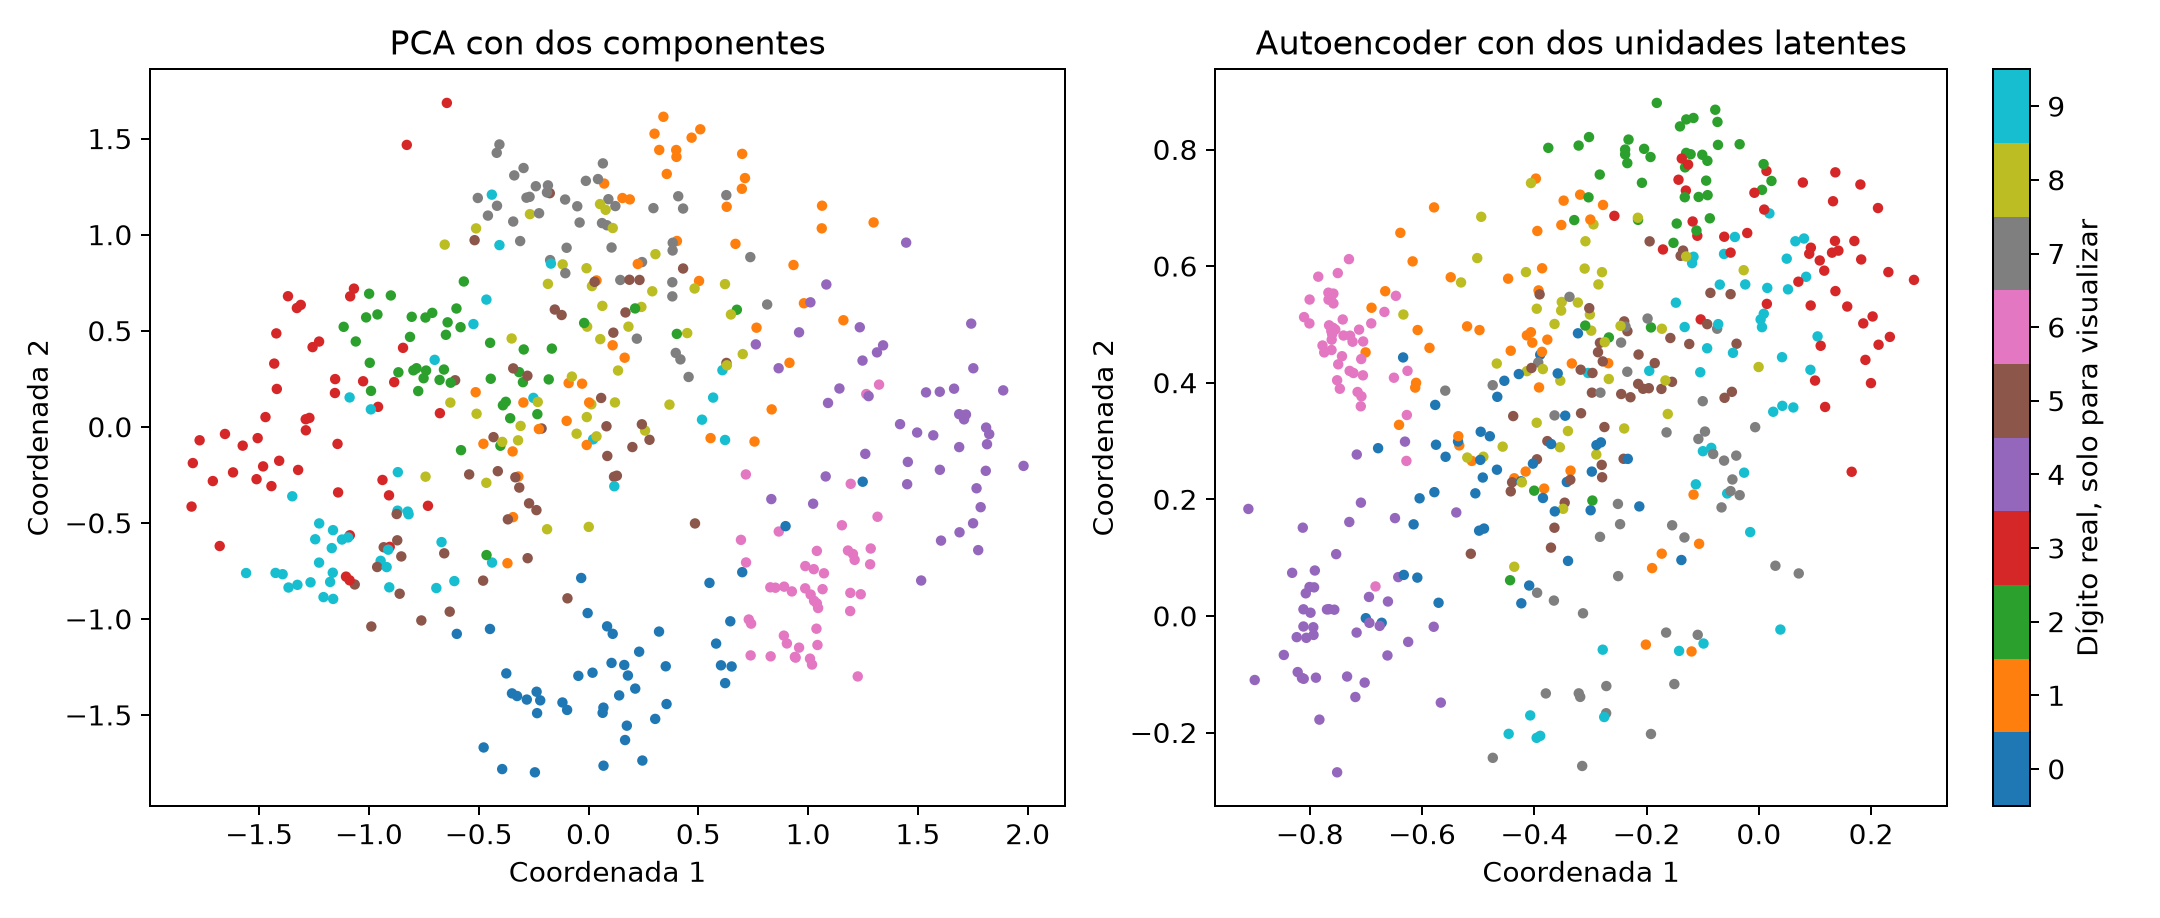

In [1]:
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs, load_wine, load_digits
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
BASE = Path.cwd()
OUT = BASE / "Figuras"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "figure.dpi": 160})
colores = ["#a71b50", "#18816c", "#43406b", "#ed6589"]
def save(fig, n):
    fig.tight_layout()
    fig.savefig(OUT / f"figura_{n}.png", dpi=180)
    plt.close(fig)
import networkx as nx
G=nx.planted_partition_graph(l=4,k=6,p_in=.75,p_out=.035,seed=42)
pos=nx.spring_layout(G,seed=42)
central=nx.betweenness_centrality(G)
fig,ax=plt.subplots(figsize=(8,6.35))
nx.draw_networkx_edges(G,pos,ax=ax,alpha=.4)
nodes=nx.draw_networkx_nodes(G,pos,ax=ax,node_size=[70+G.degree(n)*45 for n in G],node_color=[central[n] for n in G],cmap="RdPu")
ax.set_title("Grafo sintético: grado e intermediación");ax.axis("off")
fig.colorbar(nodes,ax=ax,label="Intermediación normalizada");save(fig,1)
coms=nx.community.louvain_communities(G,seed=42)
lab={n:i for i,c in enumerate(coms) for n in c}
fig,ax=plt.subplots(figsize=(8,6.35))
nx.draw_networkx(G,pos,ax=ax,with_labels=False,node_size=170,node_color=[colores[lab[n]%4] for n in G],edge_color="#bbbbbb")
ax.set_title(f"Louvain: {len(coms)} comunidades detectadas");ax.axis("off");save(fig,2)
digits=load_digits();D=digits.data/16.0
tr,te=train_test_split(np.arange(len(D)),test_size=.25,random_state=42,stratify=digits.target)
ae8=MLPRegressor(hidden_layer_sizes=(8,),activation="tanh",solver="adam",max_iter=900,random_state=42,tol=1e-5)
ae8.fit(D[tr],D[tr]);R=ae8.predict(D[te]);mse=float(np.mean((D[te]-R)**2))
fig,ax=plt.subplots(2,6,figsize=(12,4.4))
for j in range(6):
    ax[0,j].imshow(D[te[j]].reshape(8,8),cmap="gray",vmin=0,vmax=1)
    ax[1,j].imshow(R[j].reshape(8,8),cmap="gray",vmin=0,vmax=1)
    for a in ax[:,j]:a.set_xticks([]);a.set_yticks([])
ax[0,0].set_ylabel("Original");ax[1,0].set_ylabel("Reconstrucción")
fig.suptitle(f"Autoencoder 64 → 8 → 64; MSE de prueba = {mse:.4f}")
save(fig,3)
pca=PCA(n_components=2).fit(D[tr]);Zp=pca.transform(D[te])
ae2=MLPRegressor(hidden_layer_sizes=(2,),activation="tanh",max_iter=1200,random_state=42,tol=1e-5)
ae2.fit(D[tr],D[tr])
Za=np.tanh(D[te]@ae2.coefs_[0]+ae2.intercepts_[0])
fig,ax=plt.subplots(1,2,figsize=(12,5.1))
for a,Z,t in zip(ax,[Zp,Za],["PCA con dos componentes","Autoencoder con dos unidades latentes"]):
    im=a.scatter(*Z.T,c=digits.target[te],cmap="tab10",s=10,vmin=-.5,vmax=9.5)
    a.set(title=t,xlabel="Coordenada 1",ylabel="Coordenada 2")
fig.colorbar(im,ax=ax[1],ticks=range(10),label="Dígito real, solo para visualizar");save(fig,4)
print("Comunidades",len(coms),"MSE prueba AE8",mse)
